# Phase 4 scratch: network and rings (decision gate)
Nodes = rebuilt identities. Edges = shared device fingerprint, shared card1, or shared rare email domain. Hub suppression drops any value shared by more than `HUB_MAX` identities. Clusters are scored on training-period labels only.

In [1]:
import sys, json
sys.path.insert(0, '../../src')
import pandas as pd, graph, viz
pd.set_option('display.width', 250)
con = graph.connect()

## Tuning the hub threshold
Too high and popular values chain strangers into one giant blob.

In [2]:
shape = {}
for h in [10, 20, 50]:
    e = graph.build_edges(con, h)
    shape[h] = graph.graph_shape(e, graph.find_clusters(e))
pd.DataFrame(shape)

,10,20,50
linked_uids,35567,53174,77769
edges,83677,232259,741279
largest_component,4761,20293,48622
clusters,7181,6781,5668
clusters_3plus,4544,4387,3562
largest_cluster,219,2946,5537
edges_via_device,28541,77092,246352
edges_via_card,55144,155196,491852
edges_via_email,12,12,3238


## Final graph (HUB_MAX = 10)

In [3]:
con, edges, cl, c, u = graph.run()
graph.graph_shape(edges, cl)

{'linked_uids': 35567,
 'edges': 83677,
 'largest_component': 4761,
 'clusters': 7181,
 'clusters_3plus': 4544,
 'largest_cluster': 219,
 'edges_via_device': 28541,
 'edges_via_card': 55144,
 'edges_via_email': 12}

In [4]:
rings = c[graph.is_ring(c)]
print(len(rings), 'rings;', int(rings.n_uids.sum()), 'identities')
rings.head(15)

44 rings; 225 identities


,n_uids,train_txns,train_fraud,train_fraud_uids,uids_with_train,test_txns,total_amt,train_fraud_rate,via_device,via_card,via_email
cluster_id,,,,,,,,,,,
2440,4,5,5.0,4,4,1,486.0,1.0000,1.0,0.0,0.0
3573,3,4,4.0,3,3,0,1200.0,1.0000,1.0,0.0,0.0
3701,3,4,4.0,3,3,0,1200.0,1.0000,1.0,0.0,0.0
3931,3,16,16.0,3,3,0,322.0,1.0000,1.0,0.0,0.0
4146,3,5,5.0,3,3,0,1375.0,1.0000,1.0,0.0,0.0
1886,5,2,2.0,2,2,5,1018.0,1.0000,1.0,0.0,0.0
2556,4,4,4.0,2,2,11,2753.0,1.0000,1.0,0.0,0.0
2614,4,3,3.0,2,2,2,184.0,1.0000,0.0,1.0,0.0
3440,3,3,3.0,2,2,1,520.0,1.0000,0.0,1.0,0.0


In [5]:
rings[['via_device', 'via_card', 'via_email']].mean().round(2)

via_device    0.67
via_card      0.34
via_email     0.00
dtype: float64

## Gate: how much test-period fraud sits inside rings?
`own history clean` = the identity itself had no training-period fraud, so any signal is guilt by association.

In [6]:
tv = graph.test_view(con, u)
print(json.dumps(graph.gate_metrics(tv, c), indent=1))

{
 "ring_clusters": 44,
 "uids_in_rings": 225,
 "test_base_fraud_rate": 0.0344,
 "in_ring (any)": {
  "txns": 114,
  "fraud_rate": 0.64,
  "pct_of_test_fraud": 1.2,
  "pct_of_missed_fraud": 1.2,
  "missed_fraud_amt": 2079
 },
 "in_ring, own history clean": {
  "txns": 52,
  "fraud_rate": 0.385,
  "pct_of_test_fraud": 0.3,
  "pct_of_missed_fraud": 0.1,
  "missed_fraud_amt": 226
 },
 "any fraud neighbor, own history clean": {
  "txns": 10178,
  "fraud_rate": 0.115,
  "pct_of_test_fraud": 19.4,
  "pct_of_missed_fraud": 10.1,
  "missed_fraud_amt": 19248
 }
}


## Ring lifetime, and a hindsight check
The hindsight check uses test labels and is a diagnostic only, never used for evaluation.

In [7]:
con.register('cl', cl)
con.register('rid', pd.DataFrame({'cluster_id': list(rings.index)}))
life = con.sql('''SELECT cl.cluster_id, MAX(day)-MIN(day)+1 active_days,
  MAX(day) FILTER (WHERE isFraud=1) - MIN(day) FILTER (WHERE isFraud=1) + 1 fraud_days, MAX(day) last_day
  FROM identity JOIN cl USING (uid) JOIN rid USING (cluster_id) GROUP BY 1''').df()
life.describe().round(1)

,cluster_id,active_days,fraud_days,last_day
count,44.0,44.0,44.0,44.0
mean,2431.2,71.0,27.5,108.8
std,1188.1,55.0,39.7,48.4
min,219.0,1.0,1.0,28.0
25%,1722.0,23.0,1.0,73.8
50%,2585.0,62.0,13.5,101.0
75%,3360.5,111.0,33.2,160.8
max,4511.0,171.0,171.0,182.0


In [8]:
con.sql('''WITH x AS (SELECT cl.cluster_id, uid, MAX(isFraud) f FROM identity JOIN cl USING (uid) GROUP BY ALL),
  r AS (SELECT cluster_id FROM x GROUP BY 1 HAVING COUNT(*)>=3 AND SUM(f)>=2 AND AVG(f)>=0.5)
SELECT (SELECT COUNT(*) FROM r) AS hindsight_rings,
       COUNT(*) FILTER (WHERE isFraud=1) AS test_fraud_in_hindsight_rings
FROM identity JOIN cl USING (uid) WHERE day > 120 AND cluster_id IN (SELECT cluster_id FROM r)''').df()

,hindsight_rings,test_fraud_in_hindsight_rings
0,89,192


PosixPath('figures/04_cluster_size_vs_fraud.png')

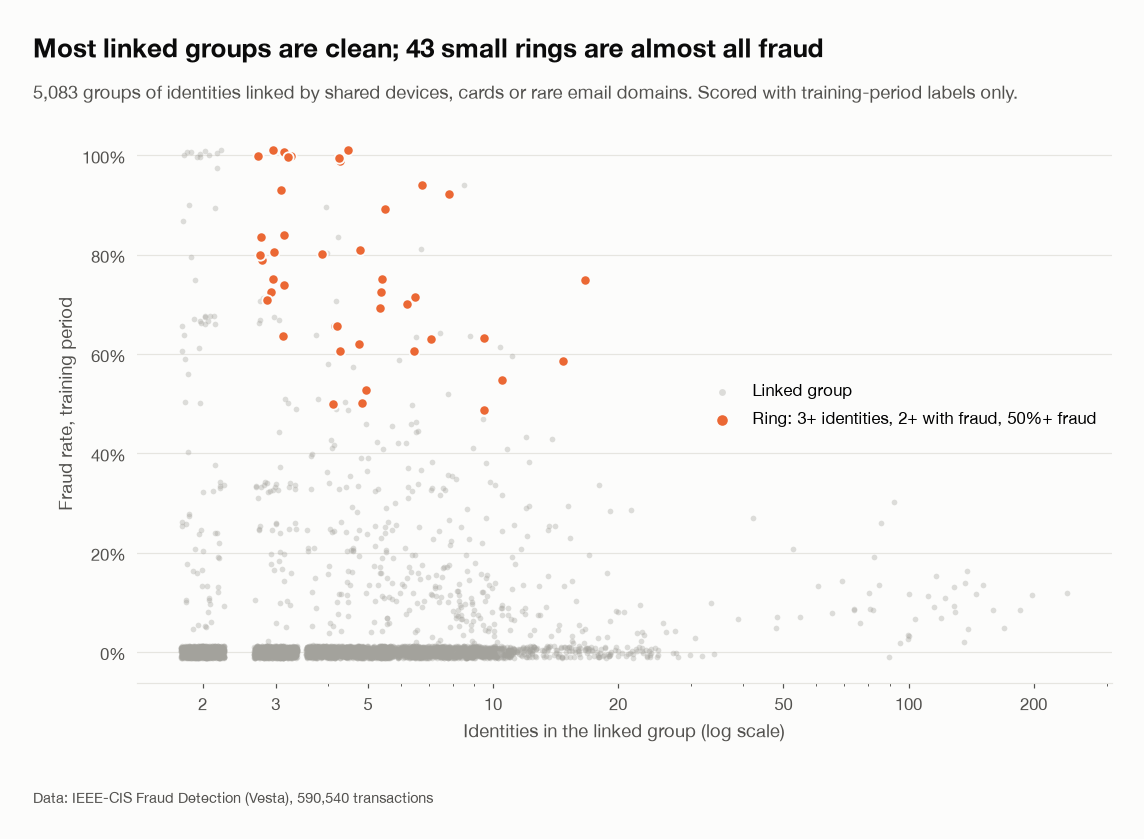

In [9]:
fig = graph.plot_size_vs_fraud(c)
viz.save(fig, '04_cluster_size_vs_fraud')